Activity Detector to hybrydowy system rozpoznawania aktywności fizycznej, łączący klasyfikator Random Forest z algorytmem regułowym. Dane z czujników Empatica E4 są dzielone na 10-sekundowe okna, z których ekstraktowane są 32 cechy statystyczne. Random Forest klasyfikuje rodzaj wysiłku jako aerobowy lub anaerobowy. Dodatkowo algorytm analizuje wzrost tętna (HR) i zmienność przyspieszenia (ACC) względem wartości bazowych. Aktywność zostaje potwierdzona, gdy oba warunki są spełnione w odpowiednio dużej liczbie okien w ciągu 5 minut. W przeciwnym przypadku system wskazuje stan spoczynku (REST).


https://www.physionet.org/content/wearable-device-dataset/1.0.1/#files-panel

In [30]:
BASE_DIR = Path(r'C:\Users\user\Desktop\hackaton\NASA-Space-Challange\wearable-model\wearable-device-dataset-1.0.1\wearable-device-dataset-from-induced-stress-and-structured-exercise-sessions-1.0.1\Wearable_Dataset')

In [8]:
import pandas as pd
import numpy as np
from pathlib import Path

In [9]:
# ==========================================
# 1. FUNKCJA WCZYTUJĄCA SYGNAŁY EMPATICA E4
# ==========================================

def load_signal(folder, filename, columns):

    raw = pd.read_csv(folder / filename, header=None)

    # Czas rozpoczęcia pomiaru
    start_time = pd.to_datetime(raw.iloc[0, 0], utc=True)

    # Częstotliwość próbkowania
    fs = float(raw.iloc[1, 0])

    # Wartości sygnału
    values = raw.iloc[2:, :len(columns)].apply(
        pd.to_numeric, errors="coerce"
    ).reset_index(drop=True)

    # Indeksy czasowe próbek
    timestamps = (
        start_time
        + pd.to_timedelta(np.arange(len(values)) / fs, unit="s")
    )

    values.index = timestamps
    values.columns = columns

    return values

In [ ]:
# ==========================================
# 2. FUNKCJA WCZYTUJĄCA CAŁĄ SESJĘ
# ==========================================

def load_session(folder, session_name, label):

    # Wczytanie sygnałów
    acc = load_signal(folder, "ACC.csv", ["ACC_x", "ACC_y", "ACC_z"])
    bvp = load_signal(folder, "BVP.csv", ["BVP"])
    eda = load_signal(folder, "EDA.csv", ["EDA"])
    temp = load_signal(folder, "TEMP.csv", ["TEMP"])
    hr = load_signal(folder, "HR.csv", ["HR"])

    # Synchronizacja sygnałów do 1 Hz
    df = pd.concat(
        [
            acc.resample("1s").mean(),
            bvp.resample("1s").mean(),
            eda.resample("1s").mean(),
            temp.resample("1s").mean(),
            hr.resample("1s").mean()
        ],
        axis=1
    )

    # Wypadkowa przyspieszenia
    df["ACC_magnitude"] = np.sqrt(
        df["ACC_x"]**2 +
        df["ACC_y"]**2 +
        df["ACC_z"]**2
    )

    # Etykiety
    df["session"] = session_name
    df["label"] = label
    df["label_encoded"] = 0 if label == "AEROBIC" else 1

    return df

In [11]:

# ==========================================
# 3. WCZYTANIE WSZYSTKICH UCZESTNIKÓW
# ==========================================

all_data = []

sessions = {
    "AEROBIC": 0,
    "ANAEROBIC": 1
}

for session_name, label in sessions.items():

    session_path = BASE_DIR / session_name

    participants = sorted(
        p for p in session_path.iterdir() if p.is_dir()
    )

    print(f"\nPrzetwarzanie {session_name}...")

    for participant_folder in participants:

        participant = participant_folder.name

        try:
            df = load_session(
                participant_folder,
                session_name,
                session_name
            )

            df["participant"] = participant

            # Zachowanie czasu pomiaru jako kolumny
            df.index.name = "timestamp"
            df = df.reset_index()

            all_data.append(df)

            print(f"OK: {participant}")

        except Exception as e:
            print(f"Pominięto {participant}: {e}")



Przetwarzanie AEROBIC...
OK: f01
OK: f02
OK: f03
OK: f04
OK: f05
OK: f06
OK: f07
OK: f08
OK: f09
OK: f10
OK: f11
OK: f12
OK: f13
OK: S01
OK: S02
OK: S03
OK: S04
OK: S05
OK: S06
OK: S07
OK: S08
OK: S09
OK: S10
OK: S11_a
OK: S11_b
OK: S13
OK: S14
OK: S15
OK: S16
OK: S17
OK: S18

Przetwarzanie ANAEROBIC...
OK: f01
OK: f02
OK: f03
OK: f04
OK: f05
OK: f06
OK: f07
OK: f08
OK: f09
OK: f10
OK: f11
OK: f12
OK: f13
OK: S01
OK: S02
OK: S03
OK: S04
OK: S05
OK: S06
OK: S07
OK: S08
OK: S09
OK: S10
OK: S11
OK: S12
OK: S13
OK: S14
OK: S15
OK: S16_a
OK: S16_b
OK: S17
OK: S18


In [12]:
# ==========================================
# 4. POŁĄCZENIE WSZYSTKICH DANYCH
# ==========================================

df_all = pd.concat(all_data, ignore_index=True)

# Uporządkowanie kolumn
df_all = df_all[
    [
        "timestamp",
        "participant",
        "session",
        "ACC_x",
        "ACC_y",
        "ACC_z",
        "ACC_magnitude",
        "BVP",
        "EDA",
        "TEMP",
        "HR",
        "label",
        "label_encoded"
    ]
]

In [13]:
# ==========================================
# 5. PODSTAWOWE INFORMACJE
# ==========================================

print("\n========== PODSUMOWANIE ==========")

print("Wymiary:", df_all.shape)

print("\nLiczba próbek dla klas:")
print(df_all["label"].value_counts())

print("\nLiczba uczestników:")
print(df_all.groupby("session")["participant"].nunique())

print("\nBrakujące wartości:")
print(df_all.isna().sum())

print("\nPierwsze rekordy:")
print(df_all.head())


========== PODSUMOWANIE ==========
Wymiary: (115963, 13)

Liczba próbek dla klas:
label
AEROBIC      65875
ANAEROBIC    50088
Name: count, dtype: int64

Liczba uczestników:
session
AEROBIC      31
ANAEROBIC    32
Name: participant, dtype: int64

Brakujące wartości:
timestamp          0
participant        0
session            0
ACC_x             36
ACC_y             36
ACC_z             36
ACC_magnitude     36
BVP               28
EDA               91
TEMP              79
HR               673
label              0
label_encoded      0
dtype: int64

Pierwsze rekordy:
                  timestamp participant  session     ACC_x     ACC_y  \
0 2013-07-04 12:06:34+00:00         f01  AEROBIC  20.59375  -3.31250   
1 2013-07-04 12:06:35+00:00         f01  AEROBIC  25.53125 -38.12500   
2 2013-07-04 12:06:36+00:00         f01  AEROBIC  22.40625 -53.00000   
3 2013-07-04 12:06:37+00:00         f01  AEROBIC  51.53125  27.81250   
4 2013-07-04 12:06:38+00:00         f01  AEROBIC  58.03125  28.71875

In [14]:
hr_nan = df_all.loc[
    df_all["HR"].isna(),
    ["timestamp", "participant", "session"]
]

print(hr_nan.to_string(index=False))

                timestamp participant   session
2013-07-04 12:06:34+00:00         f01   AEROBIC
2013-07-04 12:06:35+00:00         f01   AEROBIC
2013-07-04 12:06:36+00:00         f01   AEROBIC
2013-07-04 12:06:37+00:00         f01   AEROBIC
2013-07-04 12:06:38+00:00         f01   AEROBIC
2013-07-04 12:06:39+00:00         f01   AEROBIC
2013-07-04 12:06:40+00:00         f01   AEROBIC
2013-07-04 12:06:41+00:00         f01   AEROBIC
2013-07-04 12:06:42+00:00         f01   AEROBIC
2013-07-04 12:06:43+00:00         f01   AEROBIC
2013-07-04 12:51:33+00:00         f01   AEROBIC
2013-07-04 13:23:46+00:00         f02   AEROBIC
2013-07-04 13:23:47+00:00         f02   AEROBIC
2013-07-04 13:23:48+00:00         f02   AEROBIC
2013-07-04 13:23:49+00:00         f02   AEROBIC
2013-07-04 13:23:50+00:00         f02   AEROBIC
2013-07-04 13:23:51+00:00         f02   AEROBIC
2013-07-04 13:23:52+00:00         f02   AEROBIC
2013-07-04 13:23:53+00:00         f02   AEROBIC
2013-07-04 13:23:54+00:00         f02   

In [15]:
# Sortowanie danych chronologicznie
df_all = df_all.sort_values(
    ["participant", "session", "timestamp"]
).copy()

# Uzupełnianie brakujących wartości HR interpolacją liniową
df_all["HR"] = (
    df_all.groupby(["participant", "session"])["HR"]
    .transform(lambda x: x.interpolate(
        method="linear",
        limit_area="inside"
    ))
)

# Usunięcie pozostałych wierszy zawierających NaN
df_all = df_all.dropna().reset_index(drop=True)

In [16]:
# ==========================================
# 5. PODSTAWOWE INFORMACJE
# ==========================================

print("\n========== PODSUMOWANIE ==========")

print("Wymiary:", df_all.shape)

print("\nLiczba próbek dla klas:")
print(df_all["label"].value_counts())

print("\nLiczba uczestników:")
print(df_all.groupby("session")["participant"].nunique())

print("\nBrakujące wartości:")
print(df_all.isna().sum())

print("\nPierwsze rekordy:")
print(df_all.head())


========== PODSUMOWANIE ==========
Wymiary: (115200, 13)

Liczba próbek dla klas:
label
AEROBIC      65500
ANAEROBIC    49700
Name: count, dtype: int64

Liczba uczestników:
session
AEROBIC      31
ANAEROBIC    32
Name: participant, dtype: int64

Brakujące wartości:
timestamp        0
participant      0
session          0
ACC_x            0
ACC_y            0
ACC_z            0
ACC_magnitude    0
BVP              0
EDA              0
TEMP             0
HR               0
label            0
label_encoded    0
dtype: int64

Pierwsze rekordy:
                  timestamp participant  session     ACC_x     ACC_y  \
0 2013-03-03 17:43:47+00:00         S01  AEROBIC  53.75000  24.00000   
1 2013-03-03 17:43:48+00:00         S01  AEROBIC  53.59375  24.18750   
2 2013-03-03 17:43:49+00:00         S01  AEROBIC  54.09375  23.71875   
3 2013-03-03 17:43:50+00:00         S01  AEROBIC  53.46875  24.87500   
4 2013-03-03 17:43:51+00:00         S01  AEROBIC  52.84375  24.96875   

      ACC_z  ACC_magn

In [17]:
import numpy as np
import pandas as pd
import joblib

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

WINDOW = 10
SIGNALS = [
    "ACC_x", "ACC_y", "ACC_z", "ACC_magnitude",
    "BVP", "EDA", "TEMP", "HR"
]

features_list = []

for (participant, session), group in df_all.groupby(
    ["participant", "session"]
):

    group = group.sort_values("timestamp").reset_index(drop=True)

    for start in range(0, len(group) - WINDOW + 1, WINDOW):

        w = group.iloc[start:start + WINDOW]

        if not (w["timestamp"].diff().dt.total_seconds().dropna() == 1).all():
            continue

        f = {
            "participant": participant,
            "session": session,
            "timestamp": w["timestamp"].iloc[0],
            "label_encoded": w["label_encoded"].iloc[0]
        }

        for signal in SIGNALS:
            f[f"{signal}_mean"] = w[signal].mean()
            f[f"{signal}_std"] = w[signal].std()
            f[f"{signal}_min"] = w[signal].min()
            f[f"{signal}_max"] = w[signal].max()

        features_list.append(f)

df_features = pd.DataFrame(features_list)

print("Liczba okien:", len(df_features))

Liczba okien: 11490


In [18]:
FEATURES = [
    c for c in df_features.columns
    if c not in ["participant", "session", "timestamp", "label_encoded"]
]

models = {}
test_results = {}

participants = sorted(df_features["participant"].unique())

for participant in participants:

    person = df_features[
        df_features["participant"] == participant
    ]

    train_parts = []
    test_parts = []

    for session in ["AEROBIC", "ANAEROBIC"]:

        data = person[
            person["session"] == session
        ].sort_values("timestamp")

        if len(data) < 10:
            continue

        split = int(len(data) * 0.8)

        train_parts.append(data.iloc[:split])
        test_parts.append(data.iloc[split:])

    if len(train_parts) != 2:
        continue

    train = pd.concat(train_parts)
    test = pd.concat(test_parts)

    model = RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    model.fit(train[FEATURES], train["label_encoded"])

    test = test.copy()
    test["prediction"] = model.predict(test[FEATURES])

    models[participant] = model
    test_results[participant] = test

    print(
        participant,
        "Accuracy:",
        round(accuracy_score(test["label_encoded"], test["prediction"]), 3)
    )

S01 Accuracy: 1.0
S02 Accuracy: 1.0
S03 Accuracy: 0.852
S04 Accuracy: 1.0
S05 Accuracy: 0.952
S06 Accuracy: 1.0
S07 Accuracy: 1.0
S08 Accuracy: 1.0
S09 Accuracy: 1.0
S10 Accuracy: 1.0
S13 Accuracy: 0.769
S14 Accuracy: 1.0
S15 Accuracy: 0.922
S17 Accuracy: 1.0
S18 Accuracy: 1.0
f01 Accuracy: 1.0
f02 Accuracy: 1.0
f03 Accuracy: 0.814
f04 Accuracy: 1.0
f05 Accuracy: 1.0
f06 Accuracy: 1.0
f07 Accuracy: 0.811
f08 Accuracy: 1.0
f09 Accuracy: 1.0
f10 Accuracy: 0.938
f11 Accuracy: 1.0
f12 Accuracy: 1.0
f13 Accuracy: 0.945


In [20]:
HR_INCREASE = 1.15
ACC_MARGIN = 0.02

BASELINE_SECONDS = 60

WINDOWS_FOR_DETECTION = 30
REQUIRED_WINDOWS = 24
STOP_WINDOWS = 18

detection_results = []

for participant, test in test_results.items():

    person_raw = df_all[
        df_all["participant"] == participant
    ]

    for session, data in test.groupby("session"):

        raw = person_raw[
            person_raw["session"] == session
        ].sort_values("timestamp")

        # Pierwsza minuta jako kalibracja spoczynkowa
        first_time = raw["timestamp"].min()

        baseline = raw[
            raw["timestamp"] < first_time + pd.Timedelta(
                seconds=BASELINE_SECONDS
            )
        ]

        if len(baseline) < 30:
            continue

        hr_baseline = baseline["HR"].median()

        # Indywidualna zmienność każdej osi ACC
        acc_baseline = baseline[
            ["ACC_x", "ACC_y", "ACC_z"]
        ].std()

        data = data.sort_values("timestamp").copy()

        # Warunek HR
        data["HR_ok"] = (
            data["HR_mean"] >= hr_baseline * HR_INCREASE
        )

        # Warunek ruchu: wystarczy zwiększona zmienność jednej osi
        data["ACC_ok"] = (
            (data["ACC_x_std"] > acc_baseline["ACC_x"] + ACC_MARGIN) |
            (data["ACC_y_std"] > acc_baseline["ACC_y"] + ACC_MARGIN) |
            (data["ACC_z_std"] > acc_baseline["ACC_z"] + ACC_MARGIN)
        )

        # Oba warunki muszą być spełnione
        data["candidate"] = data["HR_ok"] & data["ACC_ok"]

        # 24 z 30 ostatnich okien muszą potwierdzać aktywność
        data["votes"] = (
            data["candidate"]
            .rolling(
                WINDOWS_FOR_DETECTION,
                min_periods=WINDOWS_FOR_DETECTION
            )
            .sum()
        )

        data["confirmed"] = data["votes"] >= REQUIRED_WINDOWS

        # Histereza: zakończenie po 3 minutach bez potwierdzenia
        active = False
        inactive_counter = 0
        states = []

        for confirmed in data["confirmed"].fillna(False):

            if confirmed:
                active = True
                inactive_counter = 0

            elif active:
                inactive_counter += 1

                if inactive_counter >= STOP_WINDOWS:
                    active = False
                    inactive_counter = 0

            states.append(active)

        data["is_active"] = states

        # Końcowy wynik
        data["activity"] = np.where(
            data["is_active"],
            data["prediction"].map({
                0: "AEROBIC",
                1: "ANAEROBIC"
            }),
            "REST"
        )

        data["participant"] = participant
        data["session"] = session

        detection_results.append(data)

df_detection = pd.concat(
    detection_results,
    ignore_index=True
)

print(df_detection[
    [
        "timestamp",
        "participant",
        "session",
        "HR_mean",
        "HR_ok",
        "ACC_ok",
        "prediction",
        "is_active",
        "activity"
    ]
].head(30))

                   timestamp participant  session  HR_mean  HR_ok  ACC_ok  \
0  2013-03-03 18:10:47+00:00         S01  AEROBIC  102.523  False    True   
1  2013-03-03 18:10:57+00:00         S01  AEROBIC   99.789  False    True   
2  2013-03-03 18:11:07+00:00         S01  AEROBIC   96.694  False    True   
3  2013-03-03 18:11:17+00:00         S01  AEROBIC   95.489  False    True   
4  2013-03-03 18:11:27+00:00         S01  AEROBIC   95.400  False    True   
5  2013-03-03 18:11:37+00:00         S01  AEROBIC   97.528  False    True   
6  2013-03-03 18:11:47+00:00         S01  AEROBIC   99.909  False    True   
7  2013-03-03 18:11:57+00:00         S01  AEROBIC  102.668  False    True   
8  2013-03-03 18:12:07+00:00         S01  AEROBIC  108.401  False    True   
9  2013-03-03 18:12:17+00:00         S01  AEROBIC  112.690   True    True   
10 2013-03-03 18:12:27+00:00         S01  AEROBIC  116.481   True   False   
11 2013-03-03 18:12:37+00:00         S01  AEROBIC  120.269   True    True   

In [21]:
summary = (
    df_detection.groupby(
        ["participant", "session", "activity"]
    )
    .size()
    .reset_index(name="windows")
)

summary["duration_min"] = (
    summary["windows"] * WINDOW / 60
)

print(summary.to_string(index=False))

participant   session  activity  windows  duration_min
        S01   AEROBIC      REST       41      6.833333
        S01 ANAEROBIC      REST       23      3.833333
        S02   AEROBIC      REST       41      6.833333
        S02 ANAEROBIC      REST       23      3.833333
        S03   AEROBIC      REST       29      4.833333
        S03 ANAEROBIC      REST       25      4.166667
        S04   AEROBIC   AEROBIC       12      2.000000
        S04   AEROBIC      REST       29      4.833333
        S04 ANAEROBIC      REST       23      3.833333
        S05   AEROBIC      REST       40      6.666667
        S05 ANAEROBIC      REST       23      3.833333
        S06   AEROBIC      REST       41      6.833333
        S06 ANAEROBIC      REST       17      2.833333
        S07   AEROBIC      REST       34      5.666667
        S07 ANAEROBIC      REST       24      4.000000
        S08   AEROBIC   AEROBIC       12      2.000000
        S08   AEROBIC      REST       29      4.833333
        S0

In [24]:
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
import pandas as pd

# Połączenie wyników testowych wszystkich uczestników
test_all = pd.concat(test_results.values(), ignore_index=True)

y_true = test_all["label_encoded"]
y_pred = test_all["prediction"]

# Ogólne metryki
print("METRYKI MODELU")
print(f"Accuracy:          {accuracy_score(y_true, y_pred):.4f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_true, y_pred):.4f}")
print(f"Precision:         {precision_score(y_true, y_pred, zero_division=0):.4f}")
print(f"Recall:            {recall_score(y_true, y_pred, zero_division=0):.4f}")
print(f"F1-score:          {f1_score(y_true, y_pred, zero_division=0):.4f}")

# Raport dla obu klas
print("\nRAPORT KLASYFIKACJI")
print(classification_report(
    y_true,
    y_pred,
    target_names=["AEROBIC", "ANAEROBIC"],
    zero_division=0
))

# Macierz pomyłek
print("MACIERZ POMYŁEK")
display(pd.DataFrame(
    confusion_matrix(y_true, y_pred),
    index=["Rzeczywiste AEROBIC", "Rzeczywiste ANAEROBIC"],
    columns=["Przewidziane AEROBIC", "Przewidziane ANAEROBIC"]
))

METRYKI MODELU
Accuracy:          0.9627
Balanced accuracy: 0.9592
Precision:         0.9775
Recall:            0.9345
F1-score:          0.9555

RAPORT KLASYFIKACJI
              precision    recall  f1-score   support

     AEROBIC       0.95      0.98      0.97      1242
   ANAEROBIC       0.98      0.93      0.96       931

    accuracy                           0.96      2173
   macro avg       0.96      0.96      0.96      2173
weighted avg       0.96      0.96      0.96      2173

MACIERZ POMYŁEK


,Przewidziane AEROBIC,Przewidziane ANAEROBIC
Rzeczywiste AEROBIC,1222,20
Rzeczywiste ANAEROBIC,61,870


In [27]:
saved_detector = {
    "models": models,
    "features": FEATURES,
    "parameters": {
        "window": WINDOW,
        "hr_increase": HR_INCREASE,
        "acc_margin": ACC_MARGIN,
        "baseline_seconds": BASELINE_SECONDS,
        "windows_for_detection": WINDOWS_FOR_DETECTION,
        "required_windows": REQUIRED_WINDOWS,
        "stop_windows": STOP_WINDOWS
    }
}

joblib.dump(saved_detector, "ACTIVITY_DETECTOR.pkl")

['ACTIVITY_DETECTOR.pkl']

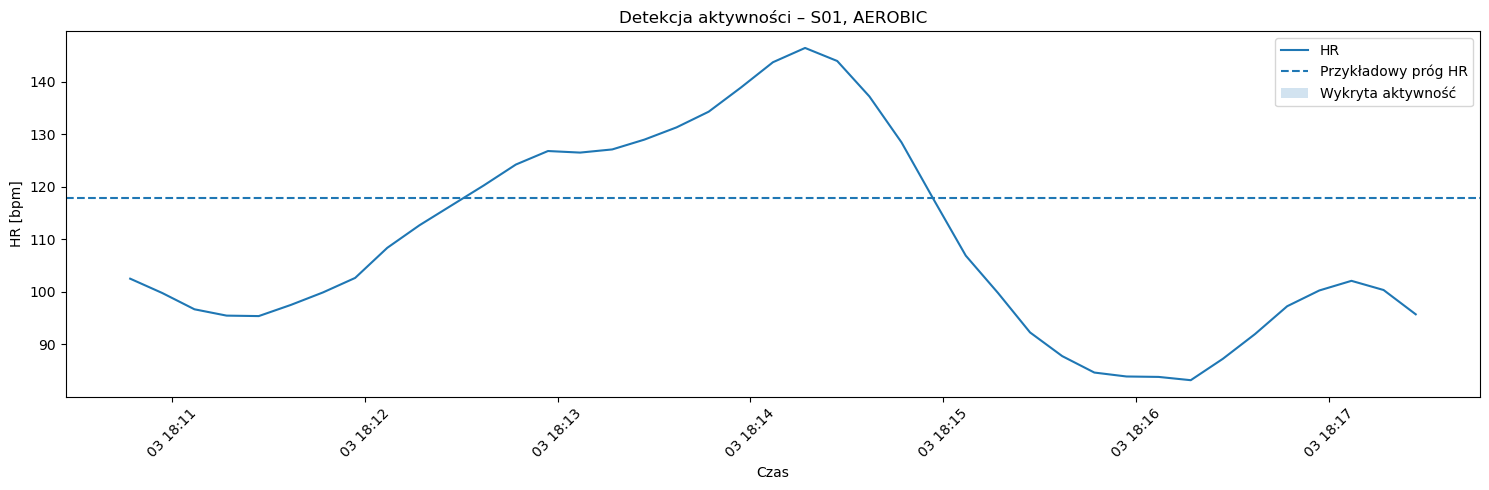

In [25]:
import matplotlib.pyplot as plt

participant = df_detection["participant"].iloc[0]
session = df_detection["session"].iloc[0]

plot_data = df_detection[
    (df_detection["participant"] == participant) &
    (df_detection["session"] == session)
].sort_values("timestamp")

plt.figure(figsize=(15, 5))

plt.plot(
    plot_data["timestamp"],
    plot_data["HR_mean"],
    label="HR",
    linewidth=1.5
)

plt.axhline(
    plot_data["HR_mean"].median() * 1.15,
    linestyle="--",
    label="Przykładowy próg HR"
)

plt.fill_between(
    plot_data["timestamp"],
    0,
    plot_data["HR_mean"],
    where=plot_data["is_active"],
    alpha=0.2,
    label="Wykryta aktywność"
)

plt.xlabel("Czas")
plt.ylabel("HR [bpm]")
plt.title(f"Detekcja aktywności – {participant}, {session}")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()